# Behavior labels: before and after

Each episode has three answers: **A1**, the Solver's first answer; **C1**, the Critic's recommended answer; and **A2**, the Solver's final answer
after seeing both. We label what A2 did.

| Label | Meaning |
|---|---|
| **Adoption** | A1 and C1 disagree, and A2 follows C1 |
| **Retention** | A1 and C1 disagree, and A2 keeps A1 |
| **Agreement** | A1 and C1 give the same answer, and A2 keeps it. Cases where both refuse and A2 keeps refusing are tagged *both refused* |
| **Out** | A2 follows neither, or the answers can't be compared reliably |

In [1]:
import json
import os
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.colors import PowerNorm
from matplotlib.patches import FancyBboxPatch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
REPORT = ROOT / "results" / "experiments" / "candidate_final_labels_20261027"
sys.path[:0] = [str(ROOT / "src"), str(REPORT)]
import final_labels
from mas_sae.experiments.records import read_jsonl

# Inputs and how to fetch them: results/experiments/candidate_final_labels_20261027/README.md
RUN_DIR = Path(os.environ.get("CANDIDATE_RUN_DIR", ROOT / "results" / "collection" / "natural_4b_full9_candidates"))
PARTITIONS = ROOT / "results" / "behavior" / "behavior_v012_official_20261011" / "partitions.csv"
FIGURES = REPORT / "figures"
FIGURES.mkdir(exist_ok=True)

approved = json.loads((REPORT / "counts.json").read_text())
records = final_labels.build(RUN_DIR, PARTITIONS)
assert final_labels.labels_sha256(records) == approved["labels_sha256"], "labels differ from the approved build"
episodes = pd.DataFrame(records)
text = {row["question_id"]: row for split in final_labels.SPLITS for row in read_jsonl(RUN_DIR / split / "interactions.jsonl")}
TOTAL = len(episodes)

INK, INK_2, RULE, GRID, WHITE, TRACK = "#0b0b0b", "#52514e", "#c9c8c3", "#e6e5e1", "#ffffff", "#ecebe7"
BLUE, ORANGE, GREEN, AMBER, LIGHT_GRAY, DARK_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#c3c2b7", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": WHITE, "axes.facecolor": WHITE, "savefig.facecolor": WHITE, "axes.edgecolor": RULE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "font.size": 10.5, "legend.frameon": False, "text.color": INK,
})
BUCKETS = ["Usable now", "Recoverable by re-evaluation", "Refusal involved", "Ambiguous", "Agreement", "Unusable"]
BUCKET_COLOURS = dict(zip(BUCKETS, [BLUE, ORANGE, GREEN, AMBER, LIGHT_GRAY, DARK_GRAY]))
GROUPS = ["adoption", "retention", "agreement", "out"]
NAMES = dict(zip(GROUPS, ["Adoption", "Retention", "Agreement", "Out / Unclassified"]))
COLOURS = dict(zip(GROUPS, [BLUE, ORANGE, GREEN, DARK_GRAY]))

buckets = episodes.six_category.value_counts().reindex(BUCKETS)
groups = episodes.label.value_counts().reindex(GROUPS)
both_refused = int((episodes["flags"].apply(lambda f: "both_refused" in f) & (episodes.label == "agreement")).sum())
before = int(episodes.v020_eligible_strict.sum())
binary, classified = int(groups["adoption"] + groups["retention"]), int(groups[GROUPS[:3]].sum())
XMAX = max(buckets.max(), groups.max()) * 1.32
pct = lambda v: f"{v:,}  ({v / TOTAL:.1%})"


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()


def table(frame, widths):
    style = frame.style.hide(axis="index").set_properties(**{"text-align": "left", "vertical-align": "top"})
    style = style.set_table_styles([{"selector": "th", "props": "text-align: left;"}])
    for column, width in widths.items():
        style = style.set_properties(subset=[column], **{"min-width": width, "max-width": width})
    display(style)

## 1. Where we started

The first labeling rules counted an episode only when A1 and C1 were two different short answers and A2 copied one of them exactly.
That left 3 in 4 sampled questions without a label.

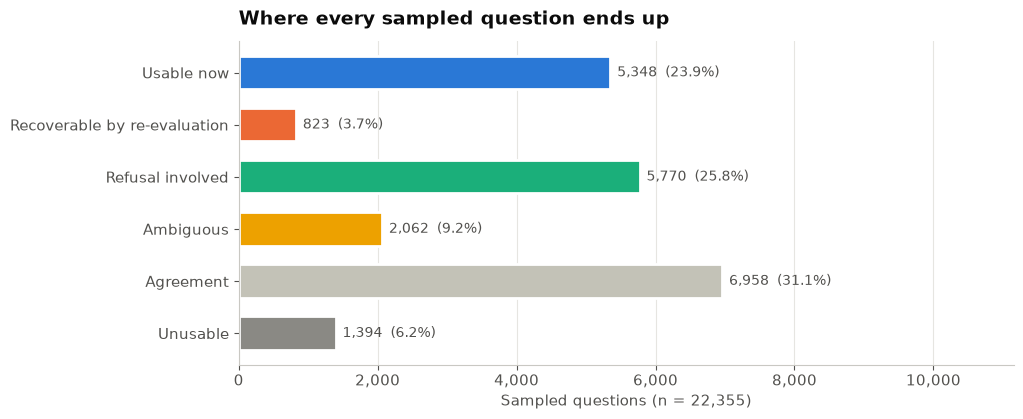

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.2))
y = list(range(len(BUCKETS)))[::-1]
bars = ax.barh(y, buckets.values, color=[BUCKET_COLOURS[b] for b in BUCKETS], height=0.64, edgecolor=WHITE, linewidth=2)
ax.set_yticks(y, BUCKETS, fontsize=11)
ax.bar_label(bars, labels=[pct(n) for n in buckets.values], padding=5, color=INK_2, fontsize=10)
ax.set_xlabel(f"Sampled questions (n = {TOTAL:,})")
ax.set_xlim(0, XMAX)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.grid(axis="y", visible=False)
ax.set_title("Where every sampled question ends up", loc="left", pad=12)
save(fig, "1_before")

## 2. Why we revised the labels

Many excluded episodes held a clear decision that the text-matching rules could not read. We revised the rules to compare what the
answers mean, using only the saved text.

In [3]:
reason = episodes.reason.str.replace(r"\s*\[.*\]$", "", regex=True)
labeled = episodes.label != "out"
count = lambda mask: f"{int((labeled & mask).sum()):,}"
refusals = ("refusal", "objection", "a1_refusal", "long_critic", "long_a1_vs_refusal", "missed_short_refusal", "R1 ",
            "E4a", "E4b", "Critic refuses or objects", "A2 refuses like")
revisions = pd.DataFrame([
    ("A refusal or objection is a real position", "C1: \"The provided text does not mention the original price …\" and A2 repeats it",
     "Adoption or Retention", count(reason.str.startswith(refusals))),
    ("The same answer can look different", "\"Eritrea was annexed by Ethiopia in 1953.\" vs. \"1953\"; \"In 1817.\" vs. \"1817\"",
     "Agreement", count(reason.str.startswith(("R3d", "same answer", "same text apart")))),
    ("Agreeing answers had no label", "A1 and C1 give the same answer, or both refuse", "Agreement",
     count(reason.str.startswith(("x_agreement", "both refused")))),
    ("A2 sometimes copied only part of a side", "A2 stops at the 64-token limit, or repeats only the first sentence", "The side A2 copied",
     count(episodes.reason.str.contains(r"\[cut off|\[letter \+ full text\]") | reason.str.startswith("A2 repeats the first"))),
], columns=["What we found", "Example", "Now labeled", "Episodes"])
table(revisions, {"What we found": "230px", "Example": "380px", "Now labeled": "150px", "Episodes": "80px"})

What we found,Example,Now labeled,Episodes
A refusal or objection is a real position,"C1: ""The provided text does not mention the original price …"" and A2 repeats it",Adoption or Retention,"4,817"
The same answer can look different,"""Eritrea was annexed by Ethiopia in 1953."" vs. ""1953""; ""In 1817."" vs. ""1817""",Agreement,515
Agreeing answers had no label,"A1 and C1 give the same answer, or both refuse",Agreement,"7,936"
A2 sometimes copied only part of a side,"A2 stops at the 64-token limit, or repeats only the first sentence",The side A2 copied,441


## 3. How the labels moved

Each cell counts questions by matching IDs between the original categories (rows) and the final labels (columns).

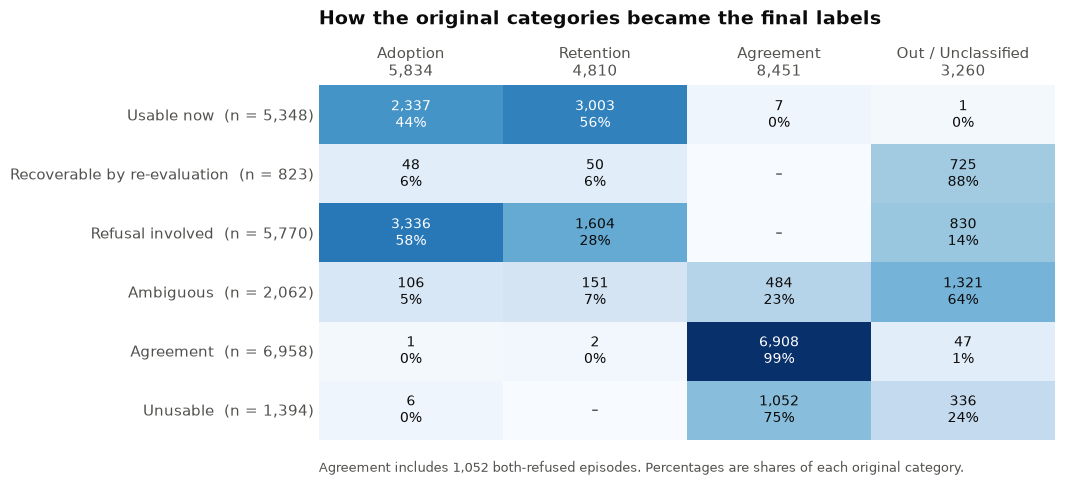

In [4]:
migration = pd.crosstab(episodes.six_category, episodes.label).reindex(index=BUCKETS, columns=GROUPS, fill_value=0)
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.imshow(migration.values, cmap="Blues", norm=PowerNorm(0.45, vmin=0, vmax=migration.values.max()), aspect="auto")
for i, bucket in enumerate(BUCKETS):
    for j, group in enumerate(GROUPS):
        v = migration.loc[bucket, group]
        ax.text(j, i, f"{v:,}\n{v / buckets[bucket]:.0%}" if v else "–", ha="center", va="center", fontsize=10,
                color=WHITE if v > migration.values.max() * 0.3 else INK)
ax.set_xticks(range(len(GROUPS)), [f"{NAMES[g]}\n{groups[g]:,}" for g in GROUPS], fontsize=10.5)
ax.set_yticks(range(len(BUCKETS)), [f"{b}  (n = {buckets[b]:,})" for b in BUCKETS], fontsize=10.5)
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("How the original categories became the final labels", loc="left", pad=44)
ax.text(0, -0.06, f"Agreement includes {both_refused:,} both-refused episodes. Percentages are shares of each original category.",
        fontsize=9.5, color=INK_2, transform=ax.transAxes, va="top")
save(fig, "3_migration")

## 4. Examples

In [5]:
EXAMPLES = [  # (question ID, change, expected label, why)
    ("2hop__315951_1094", "Refusal → Adoption", "adoption", "A2 took the Critic's refusal (the Critic was Candidate A here)."),
    ("2hop__650240_59201", "Refusal → Adoption", "adoption", "A2 repeated the Critic's refusal instead of A1's name."),
    ("2hop__131828_84128", "Objection → Retention", "retention", "The Critic objected to the question; A2 kept A1."),
    ("2hop__749069_529125", "Objection → Retention", "retention", "The Critic objected to the question; A2 kept A1."),
    ("3hop1__340016_10383_15069", "Long vs. short → Agreement", "agreement", "A1's sentence states 1953, the Critic's answer."),
    ("2hop__827538_34197", "Long vs. short → Agreement", "agreement", "A1's sentence gives 30,000, the Critic's number."),
    ("2hop__81341_86951", "Both refused → Agreement", "agreement", "Both refused and A2 kept refusing (tagged both refused)."),
    ("2hop__105388_90561", "Both refused → Agreement", "agreement", "A1 refused, the Critic objected, and A2 kept refusing."),
    ("2hop__529887_4018", "Third answer → Out", "out", "A2 said June to October, which neither side said."),
    ("2hop__147094_11125", "Neither side → Out", "out", "Both sides answered, but A2 refused on its own."),
]
by_id = episodes.set_index("question_id")
assert all(by_id.loc[q, "partition"] == "train" and by_id.loc[q, "label"] == label for q, _, label, _ in EXAMPLES)
short = lambda t: textwrap.shorten(t or "", 120, placeholder=" …")
table(pd.DataFrame([{"Change": change, "Question": short(text[q]["question"]), "A1": short(text[q]["solver_attempt_1"]),
                     "C1": short(text[q]["critic_advocated_answer"]), "A2": short(text[q]["solver_attempt_2"]),
                     "Label": NAMES[label], "Why": why, "ID": q} for q, change, label, why in EXAMPLES]),
      {"Change": "110px", "Question": "190px", "A1": "150px", "C1": "180px", "A2": "150px", "Label": "80px", "Why": "180px", "ID": "90px"})

Change,Question,A1,C1,A2,Label,Why,ID
Refusal → Adoption,What was the original price for a replacement battery from Rhapsody's developer?,US$99,The provided text does not mention the original price for a replacement battery from Rhapsody's developer.,Candidate A (the reviewer's recommendation): The provided text does not mention the original price for a replacement …,Adoption,A2 took the Critic's refusal (the Critic was Candidate A here).,2hop__315951_1094
Refusal → Adoption,What player has played for both liverpool manchester united everton and the team Chris Beech is associated with?,Peter Beardsley,"No player is mentioned in the provided paragraphs who has played for Liverpool, Manchester United, Everton, and the …","No player is mentioned in the provided paragraphs who has played for Liverpool, Manchester United, Everton, and the …",Adoption,A2 repeated the Critic's refusal instead of A1's name.,2hop__650240_59201
Objection → Retention,How long is a governor's term in WVPL's state?,Four years,"WVPL is a radio station, not a state, so it does not have a governor's term.",Four years,Retention,The Critic objected to the question; A2 kept A1.,2hop__131828_84128
Objection → Retention,What is the capital of the county located in the administrative territorial entity of Mountain Retreat?,Calaveras County,"Mountain Retreat is an unincorporated community, not a county, and therefore does not have a capital.",Calaveras County,Retention,The Critic objected to the question; A2 kept A1.,2hop__749069_529125
Long vs. short → Agreement,"When was Eritrea annexed by the Horn of Africa country where, along with Kenya, Somalia, and the country where …",Eritrea was annexed by Ethiopia in 1953.,1953,Eritrea was annexed by Ethiopia in 1953.,Agreement,"A1's sentence states 1953, the Critic's answer.",3hop1__340016_10383_15069
Long vs. short → Agreement,How many people died from the fighting between Armenia and the country where Meyniman is located?,"An estimated 30,000 people had been killed and over a million had been displaced.",30000,"An estimated 30,000 people had been killed and over a million had been displaced.",Agreement,"A1's sentence gives 30,000, the Critic's number.",2hop__827538_34197
Both refused → Agreement,When did the highest paid NBA player get his first ring?,The provided text does not contain information about when the highest-paid NBA player got his first ring.,The provided text does not contain information about when the highest-paid NBA player got his first ring.,The provided text does not contain information about when the highest-paid NBA player got his first ring.,Agreement,Both refused and A2 kept refusing (tagged both refused).,2hop__81341_86951
Both refused → Agreement,When did the country of Soup for Life gain independence from Great Britain?,The provided text does not contain information about the country of Soup for Life or its independence from Great …,Soup of Life is not a country and did not gain independence from Great Britain.,The provided text does not contain information about the country of Soup for Life or its independence from Great …,Agreement,"A1 refused, the Critic objected, and A2 kept refusing.",2hop__105388_90561
Third answer → Out,When is the dry season on the country where Kasongo Lunda is located?,The dry season runs from November to May.,The dry season in the country where Kasongo Lunda is located (the Democratic Republic of Congo) is from June to …,The dry season in the country where Kasongo Lunda is located (the Democratic Republic of Congo) is from June to October.,Out / Unclassified,"A2 said June to October, which neither side said.",2hop__529887_4018
Neither side → Out,When does the monsoon season occur in the city where André Bloc died?,"November 8, 1966.",June to September,Insufficient evidence,Out / Unclassified,"Both sides answered, but A2 refused on its own.",2hop__147094_11125


## 5. Where we ended

The same scale as section 1. Both refused is shown inside Agreement, not as a separate class.

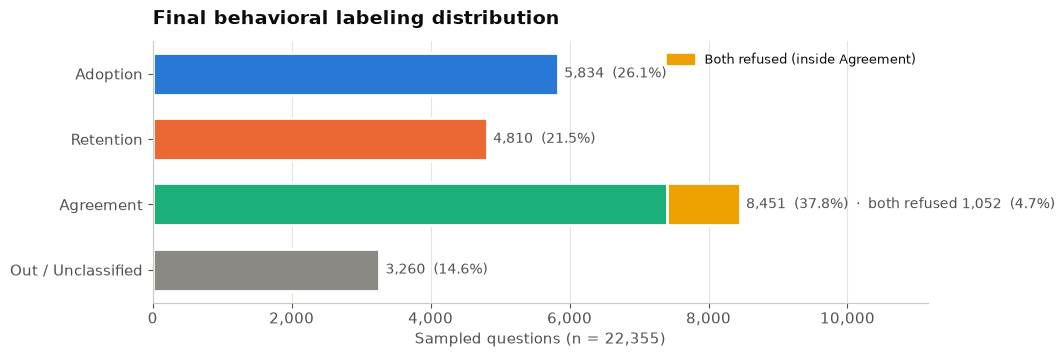

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.4))
y = list(range(len(GROUPS)))[::-1]
values = groups.copy()
values["agreement"] -= both_refused
ax.barh(y, values.values, color=[COLOURS[g] for g in GROUPS], height=0.64, edgecolor=WHITE, linewidth=2)
ax.barh(y[2], both_refused, left=values["agreement"], color=AMBER, height=0.64, edgecolor=WHITE, linewidth=2)
for yi, g in zip(y, GROUPS):
    note = f"  ·  both refused {pct(both_refused)}" if g == "agreement" else ""
    ax.text(groups[g] + XMAX * 0.008, yi, pct(groups[g]) + note, va="center", color=INK_2, fontsize=10)
ax.set_yticks(y, [NAMES[g] for g in GROUPS], fontsize=11)
ax.set_xlabel(f"Sampled questions (n = {TOTAL:,})")
ax.set_xlim(0, XMAX)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=AMBER)], labels=["Both refused (inside Agreement)"], loc="upper right", fontsize=9.5)
ax.set_title("Final behavioral labeling distribution", loc="left", pad=12)
save(fig, "5_after")

## 6. Before vs. after

Adoption/retention coverage is the like-for-like comparison, because the original rules labeled only those two. The three-class figure also
counts Agreement, which the original rules never labeled.

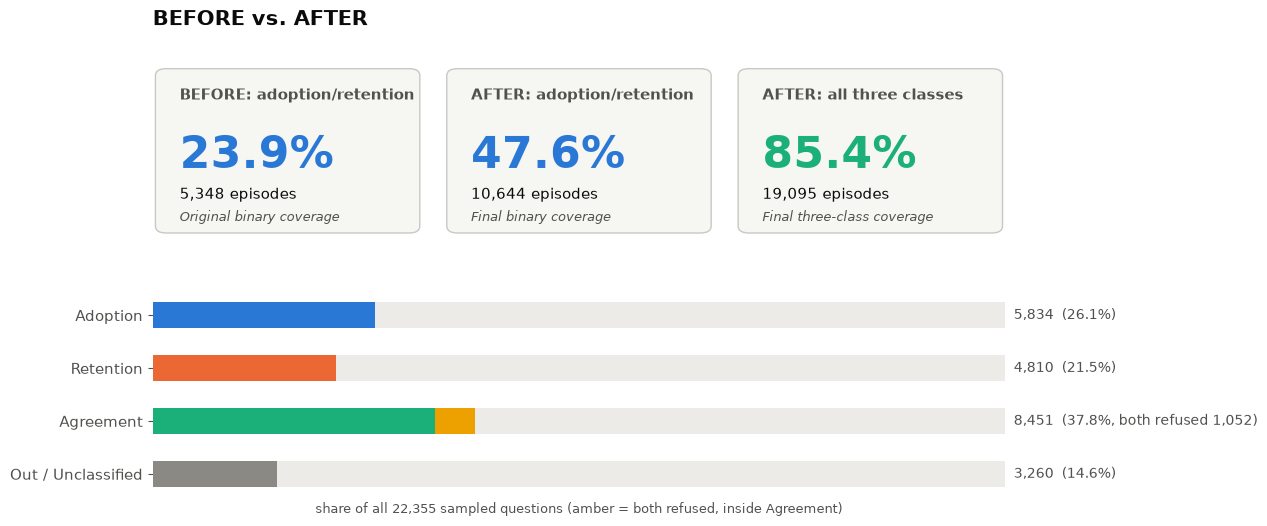

In [7]:
fig = plt.figure(figsize=(11, 5.6))
grid = fig.add_gridspec(2, 3, height_ratios=[1.05, 1.25], hspace=0.3, wspace=0.08)
cards = [("BEFORE: adoption/retention", before, "Original binary coverage", BLUE),
         ("AFTER: adoption/retention", binary, "Final binary coverage", BLUE),
         ("AFTER: all three classes", classified, "Final three-class coverage", GREEN)]
for column, (head, n, caption, colour) in enumerate(cards):
    ax = fig.add_subplot(grid[0, column])
    ax.axis("off")
    ax.add_patch(FancyBboxPatch((0.03, 0.04), 0.94, 0.92, boxstyle="round,pad=0.02,rounding_size=0.04",
                                facecolor="#f6f6f3", edgecolor=RULE, linewidth=1, transform=ax.transAxes))
    ax.text(0.1, 0.80, head, fontsize=10.5, fontweight="bold", color=INK_2, transform=ax.transAxes)
    ax.text(0.1, 0.40, f"{n / TOTAL:.1%}", fontsize=32, fontweight="bold", color=colour, transform=ax.transAxes)
    ax.text(0.1, 0.22, f"{n:,} episodes", fontsize=10.5, color=INK, transform=ax.transAxes)
    ax.text(0.1, 0.09, caption, fontsize=9, color=INK_2, style="italic", transform=ax.transAxes)
ax = fig.add_subplot(grid[1, :])
y = list(range(len(GROUPS)))[::-1]
ax.barh(y, [1] * len(GROUPS), color=TRACK, height=0.5)
for yi, g in zip(y, GROUPS):
    width = groups[g] / TOTAL
    if g == "agreement":
        ax.barh(yi, width - both_refused / TOTAL, color=GREEN, height=0.5)
        ax.barh(yi, both_refused / TOTAL, left=width - both_refused / TOTAL, color=AMBER, height=0.5)
    else:
        ax.barh(yi, width, color=COLOURS[g], height=0.5)
    note = f", both refused {both_refused:,}" if g == "agreement" else ""
    ax.text(1.01, yi, f"{groups[g]:,}  ({width:.1%}{note})", va="center", fontsize=10, color=INK_2)
ax.set_yticks(y, [NAMES[g] for g in GROUPS], fontsize=11)
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_xlabel(f"share of all {TOTAL:,} sampled questions (amber = both refused, inside Agreement)", fontsize=9)
fig.suptitle("BEFORE vs. AFTER", x=0.125, ha="left", fontsize=15, fontweight="bold", y=0.98)
save(fig, "6_before_after")

## 7. Why it matters for the SAE research

* **About twice as many adoption/retention examples** for the probes, plus Agreement as a third class, with the frozen train,
  validation, test and intervention splits unchanged.
* **Causal experiments** use adoption and retention on the intervention split. Letter-only replies and other flagged cases stay out of the
  primary set and serve as sensitivity checks.
* **More coverage is not more accuracy.** The rules were checked on train examples, and the remaining Out cases are the ones the text
  cannot settle. Validation details are in `results/experiments/candidate_final_labels_20261027/AUDIT.md`.

In [8]:
# Checks (details in AUDIT.md)
assert TOTAL == episodes.question_id.nunique() == buckets.sum() == groups.sum() == migration.to_numpy().sum()
assert (migration.sum(axis=1) == buckets).all() and (migration.sum() == groups).all()
assert episodes.loc[episodes.partition.isna(), "label"].eq("out").all()
print(f"All checks passed: {TOTAL:,} questions; before {before:,} adoption/retention; after {binary:,} adoption/retention, "
      f"{classified:,} in three classes; nothing without a frozen partition is labeled.")

All checks passed: 22,355 questions; before 5,348 adoption/retention; after 10,644 adoption/retention, 19,095 in three classes; nothing without a frozen partition is labeled.
